# moonshot_ml_sandbox — V2: market-residualized target

**What changes from V1: only the target.** V1 predicted each stock's *absolute*
forward return. V2 predicts its **market-residualized** forward return:

`residual_target = fwd_ret_20d  -  (equal-weighted mean fwd_ret_20d that day)`

Everything else — the five z-scored features, the rolling 3yr/1yr folds, the
purge gap, the exact + gradient-descent solves, the IC scoring — is **identical
to V1**. Holding all of that fixed makes this a *controlled experiment*: any
change in R2 / IC / weights is attributable to the target change alone.

**Why we're doing this (the diagnostic framing).** V1 left three confounded
explanations for its low R2:
1. **market-direction ceiling** — cross-sectional (market-neutral) features can't
   explain the market-wide component of an absolute target. *(near-certain, large)*
2. **regime-varying weights** — one fixed linear fit per fold, but the true
   coefficients move within the period. *(evidenced)*
3. **genuine nonlinearity** — curvature a straight line can't fit. *(unconfirmed)*

V2 **peels off cause #1**. The residualized target has the market component
removed, so cross-sectional features finally have a fair shot. **Prediction: R2
rises substantially.** If it barely moves, that would be surprising and would
shift weight onto causes #2/#3.

**The market return is the per-day mean of `fwd_ret_20d`.** This isn't a
shortcut: an equal-weighted portfolio's return *is* the arithmetic mean of its
constituents' returns, by definition. We subtract the mean computed over exactly
the eligible cards each day (the V1 dataset is already filtered to those), and
prove the residual is mean-zero per day.

This is a learning exercise, not a strategy test. Writes figures only.

## Cell 0 — Mount + load the V1 dataset (read-only)

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
datasets = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))
assert datasets, f"No V1 dataset in {SANDBOX_DIR}."
DATASET_PATH = datasets[-1]
print(f"Loading (READ-ONLY): {DATASET_PATH.name}")

Mounted at /content/drive
Loading (READ-ONLY): ml_sandbox_v1_dataset_2026-09-07.parquet


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

df = pd.read_parquet(DATASET_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "ticker"]).reset_index(drop=True)

RAW = ["momentum_12_1","reversal_1m","realized_vol_60","log_turnover","overnight_drift"]
Z   = [f + "_z" for f in RAW]
TARGET_ABS = "fwd_ret_20d"          # V1 absolute target (kept for comparison)
TARGET_RES = "fwd_ret_20d_resid"    # V2 residualized target (built below)
NICE = {"momentum_12_1":"Momentum","reversal_1m":"Reversal","realized_vol_60":"Realized vol",
        "log_turnover":"Log-turnover","overnight_drift":"Overnight drift"}

EXPORT_DIR = SANDBOX_DIR / "viz_exports_v2"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_fig = {"n": 0}
def save_fig(fig, name):
    _fig["n"] += 1
    p = EXPORT_DIR / f"{_fig['n']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")

colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
print(f"{len(df):,} cards | {df['date'].min().date()} -> {df['date'].max().date()}")

1,813,407 cards | 2011-01-03 -> 2026-06-10


## Cell 1 — Build the residualized target + prove it's clean

The market return each day is the equal-weighted mean of `fwd_ret_20d` over that
day's eligible cards. The residual target subtracts it. Two proofs follow:
- **mean-zero check**: each day's residual target must average ~0 (that's what
  "subtracted the mean" means — if it isn't ~0, the averaging set was wrong).
- **decomposition check**: `resid + market == absolute` exactly, per row.

In [3]:
# market forward return per day = equal-weighted mean of fwd_ret_20d (by definition)
market_ret = df.groupby("date")[TARGET_ABS].transform("mean")
df[TARGET_RES] = df[TARGET_ABS] - market_ret

# PROOF 1 — residual is mean-zero within each day
daily_mean_resid = df.groupby("date")[TARGET_RES].mean()
print("PROOF 1 — per-day mean of residual target (must be ~0):")
print(f"  max |daily mean residual| = {daily_mean_resid.abs().max():.2e}  "
      f"(machine-zero confirms correct demeaning)")

# PROOF 2 — exact decomposition: residual + market == absolute
recon = df[TARGET_RES] + market_ret
print(f"\nPROOF 2 — max |(_resid + market) - absolute| = "
      f"{(recon - df[TARGET_ABS]).abs().max():.2e}  (exact decomposition)")

# how big IS the market component we removed? (context for the R2 change to come)
var_abs = df[TARGET_ABS].var()
var_mkt = market_ret.var()
var_res = df[TARGET_RES].var()
print(f"\nVariance decomposition of the target:")
print(f"  var(absolute)      = {var_abs:.5f}")
print(f"  var(market comp.)  = {var_mkt:.5f}  ({100*var_mkt/var_abs:.1f}% of absolute)")
print(f"  var(residual)      = {var_res:.5f}  ({100*var_res/var_abs:.1f}% of absolute)")
print("  -> the market slice we removed is variance the cross-sectional features "
      "could NEVER explain. Removing it is why V2's R2 should rise.")
print("\n  NOTE: the market's share of TOTAL variance may look modest (idiosyncratic")
print("  cross-sectional dispersion across ~480 names is large). Don't judge the")
print("  effect by that share alone: because V1's absolute R2 was ~0, even removing")
print("  a modest market slice can lift R2 a lot in RELATIVE terms. Read the R2")
print("  CHANGE (Chart 3), not just the market share.")

PROOF 1 — per-day mean of residual target (must be ~0):
  max |daily mean residual| = 5.67e-17  (machine-zero confirms correct demeaning)

PROOF 2 — max |(_resid + market) - absolute| = 2.22e-16  (exact decomposition)

Variance decomposition of the target:
  var(absolute)      = 0.01481
  var(market comp.)  = 0.00424  (28.6% of absolute)
  var(residual)      = 0.01057  (71.4% of absolute)
  -> the market slice we removed is variance the cross-sectional features could NEVER explain. Removing it is why V2's R2 should rise.

  NOTE: the market's share of TOTAL variance may look modest (idiosyncratic
  cross-sectional dispersion across ~480 names is large). Don't judge the
  effect by that share alone: because V1's absolute R2 was ~0, even removing
  a modest market slice can lift R2 a lot in RELATIVE terms. Read the R2
  CHANGE (Chart 3), not just the market share.


  [saved: 01_market_component.png]


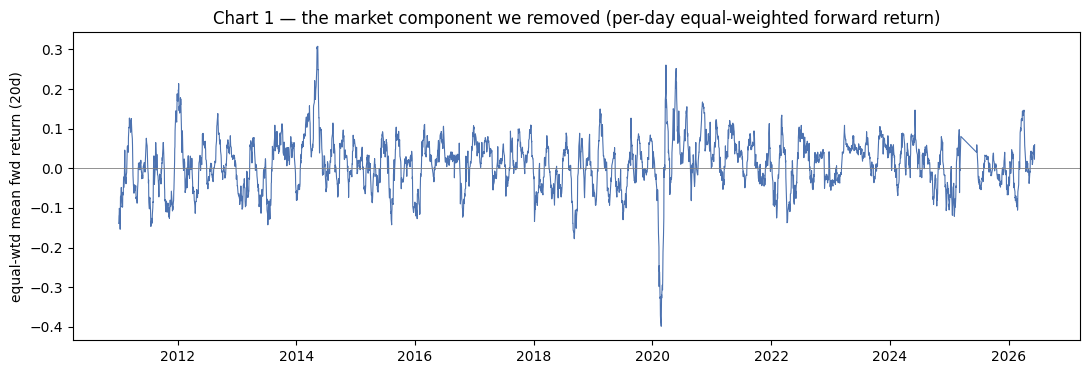

Big swings here (2020 crash, recoveries) are exactly the market-direction variance the cross-sectional features cannot see. V2 removes it from the target.


In [4]:
# CHART 1 — the market forward return over time (what we subtracted)
fig, ax = plt.subplots(figsize=(13, 4))
mkt_by_date = df.groupby("date")[TARGET_ABS].mean()
ax.plot(mkt_by_date.index, mkt_by_date.values, lw=0.8, color="#4C72B0")
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("equal-wtd mean fwd return (20d)")
ax.set_title("Chart 1 — the market component we removed (per-day equal-weighted forward return)")
save_fig(fig, "market_component"); plt.show()
print("Big swings here (2020 crash, recoveries) are exactly the market-direction "
      "variance the cross-sectional features cannot see. V2 removes it from the target.")

  [saved: 02_target_dist_compare.png]


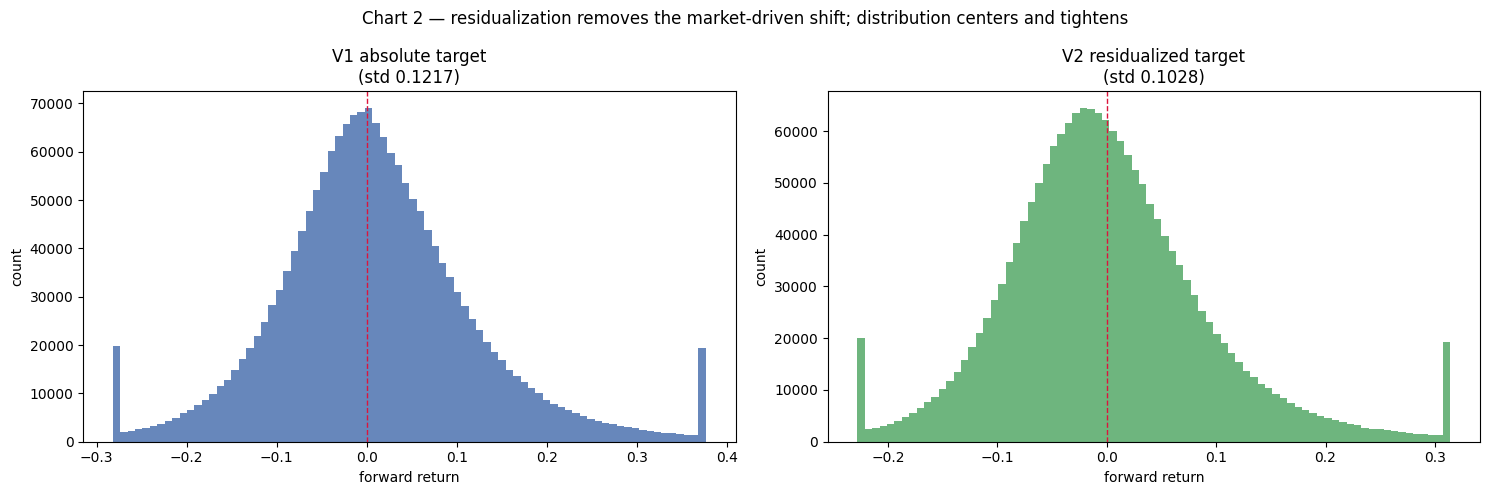

In [5]:
# CHART 2 — absolute vs residualized target distribution (same shape, tighter)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, title, c in [(a1, TARGET_ABS, "V1 absolute target", "#4C72B0"),
                          (a2, TARGET_RES, "V2 residualized target", "#55A868")]:
    x = df[col].to_numpy()
    lo, hi = np.percentile(x, [1, 99])
    ax.hist(np.clip(x, lo, hi), bins=80, color=c, alpha=0.85)
    ax.axvline(0, color="crimson", lw=1, ls="--")
    ax.set_title(f"{title}\n(std {x.std():.4f})")
    ax.set_xlabel("forward return"); ax.set_ylabel("count")
fig.suptitle("Chart 2 — residualization removes the market-driven shift; "
             "distribution centers and tightens", fontsize=12)
fig.tight_layout(); save_fig(fig, "target_dist_compare"); plt.show()

## Cell 2 — Rebuild the V1 regression machinery (identical) and run BOTH targets

We reuse the exact same fold definitions, purge, exact-solve, and IC scoring from
V1, and run the whole thing twice — once on the absolute target, once on the
residualized target — so every number is directly comparable.

In [6]:
all_dates = np.array(sorted(df["date"].unique()))

folds = []
for y0 in range(2011, 2023):
    train_lo, train_hi = pd.Timestamp(f"{y0}-01-01"), pd.Timestamp(f"{y0+2}-12-31")
    test_lo, test_hi   = pd.Timestamp(f"{y0+3}-01-01"), pd.Timestamp(f"{y0+3}-12-31")
    if test_lo > df["date"].max(): break
    hi_pos = np.searchsorted(all_dates, np.datetime64(train_hi), side="right") - 1
    purge_from = pd.Timestamp(all_dates[hi_pos - 21 + 1])
    folds.append(dict(y0=y0, train_lo=train_lo, train_hi=train_hi,
                      test_lo=test_lo, test_hi=test_hi, purge_from=purge_from))

def make_fold(f):
    tr = df[(df["date"] >= f["train_lo"]) & (df["date"] < f["purge_from"])]
    te = df[(df["date"] >= f["test_lo"]) & (df["date"] <= f["test_hi"])]
    return tr, te

def add_intercept(X): return np.column_stack([np.ones(len(X)), X])

def fit_exact(train, target):
    X = add_intercept(train[Z].to_numpy()); y = train[target].to_numpy()
    coef, *_ = np.linalg.lstsq(X, y, rcond=None); return coef

def score_fold(coef, test, target):
    X = add_intercept(test[Z].to_numpy()); pred = X @ coef
    actual = test[target].to_numpy()
    ss_res = np.sum((actual - pred)**2); ss_tot = np.sum((actual - actual.mean())**2)
    r2 = 1 - ss_res/ss_tot
    tmp = test[["date"]].copy(); tmp["pred"] = pred; tmp["actual"] = actual
    rank = [spearmanr(g["pred"], g["actual"]).correlation
            for _, g in tmp.groupby("date") if len(g) >= 30]
    rank = np.array(rank)
    return dict(r2=r2, ic_rank=np.nanmean(rank), pct_pos=np.mean(rank > 0),
                daily_rank_ic=rank, test_dates=sorted(tmp["date"].unique()))

def run_all(target):
    weights, scores = [], []
    for f in folds:
        tr, te = make_fold(f)
        coef = fit_exact(tr, target)
        s = score_fold(coef, te, target); s["test_year"] = f["y0"]+3
        weights.append(coef); scores.append(s)
    return weights, scores

W_abs, S_abs = run_all(TARGET_ABS)   # V1 replica
W_res, S_res = run_all(TARGET_RES)   # V2

def summ(scores):
    return pd.DataFrame([{k: s[k] for k in ["test_year","r2","ic_rank","pct_pos"]}
                         for s in scores])
sa, sr = summ(S_abs), summ(S_res)
print("ABSOLUTE target (V1 replica):")
print(sa.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"  pooled: R2 {sa.r2.mean():+.4f} | rank IC {sa.ic_rank.mean():+.4f} | days+ {sa.pct_pos.mean()*100:.0f}%")
print("\nRESIDUALIZED target (V2):")
print(sr.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"  pooled: R2 {sr.r2.mean():+.4f} | rank IC {sr.ic_rank.mean():+.4f} | days+ {sr.pct_pos.mean()*100:.0f}%")

ABSOLUTE target (V1 replica):
 test_year      r2  ic_rank  pct_pos
      2014 -0.1107  +0.0930  +0.7172
      2015 -0.0305  +0.0791  +0.7702
      2016 -0.0029  +0.0141  +0.5425
      2017 -0.0142  +0.0513  +0.6653
      2018 -0.0846  +0.0890  +0.7154
      2019 +0.0091  +0.1460  +0.7224
      2020 -0.0249  +0.0291  +0.5339
      2021 -0.0776  +0.0421  +0.5887
      2022 -0.0311  +0.0252  +0.6492
      2023 -0.0113  +0.0189  +0.6612
      2024 -0.0086  -0.0018  +0.5285
      2025 -0.1185  +0.0623  +0.7366
  pooled: R2 -0.0421 | rank IC +0.0540 | days+ 65%

RESIDUALIZED target (V2):
 test_year      r2  ic_rank  pct_pos
      2014 +0.0002  +0.0930  +0.7172
      2015 +0.0030  +0.0791  +0.7702
      2016 -0.0038  +0.0141  +0.5425
      2017 +0.0007  +0.0513  +0.6653
      2018 +0.0045  +0.0890  +0.7154
      2019 +0.0199  +0.1460  +0.7224
      2020 -0.0072  +0.0291  +0.5339
      2021 -0.0077  +0.0421  +0.5887
      2022 -0.0065  +0.0252  +0.6492
      2023 -0.0003  +0.0189  +0.6612
    

## Cell 3 — The head-to-head comparison (the payoff)

Because only the target changed, these differences isolate the effect of removing
the market-direction ceiling.

  [saved: 03_r2_compare.png]


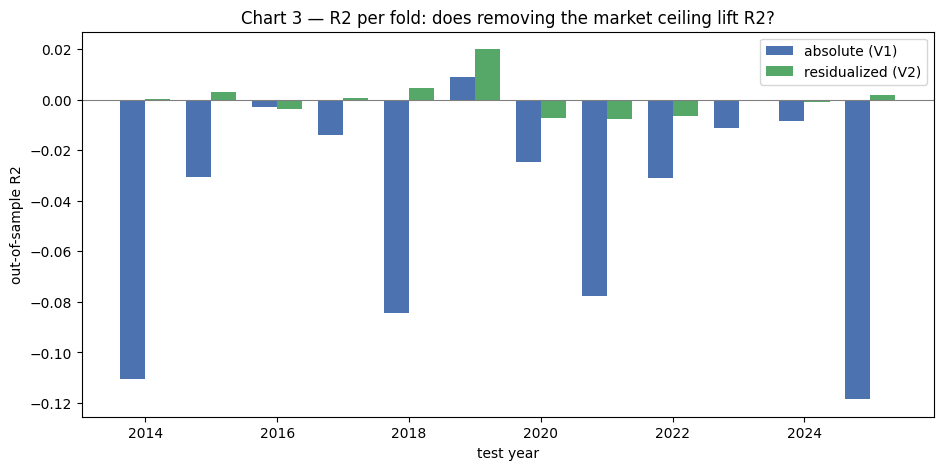

Pooled R2: absolute -0.0421 -> residualized +0.0003.
If V2 bars sit clearly above V1 bars, cause #1 (market ceiling) was a big part of V1's low R2 — confirming the V1 finding-(b) decomposition.


In [7]:
# CHART 3 — R2 per fold, absolute vs residualized
fig, ax = plt.subplots(figsize=(11, 5))
yrs = sa["test_year"].to_numpy()
w = 0.38
ax.bar(yrs - w/2, sa["r2"], w, label="absolute (V1)", color="#4C72B0")
ax.bar(yrs + w/2, sr["r2"], w, label="residualized (V2)", color="#55A868")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("test year"); ax.set_ylabel("out-of-sample R2")
ax.set_title("Chart 3 — R2 per fold: does removing the market ceiling lift R2?")
ax.legend()
save_fig(fig, "r2_compare"); plt.show()
print(f"Pooled R2: absolute {sa.r2.mean():+.4f} -> residualized {sr.r2.mean():+.4f}.")
print("If V2 bars sit clearly above V1 bars, cause #1 (market ceiling) was a big "
      "part of V1's low R2 — confirming the V1 finding-(b) decomposition.")

  [saved: 04_ic_compare.png]


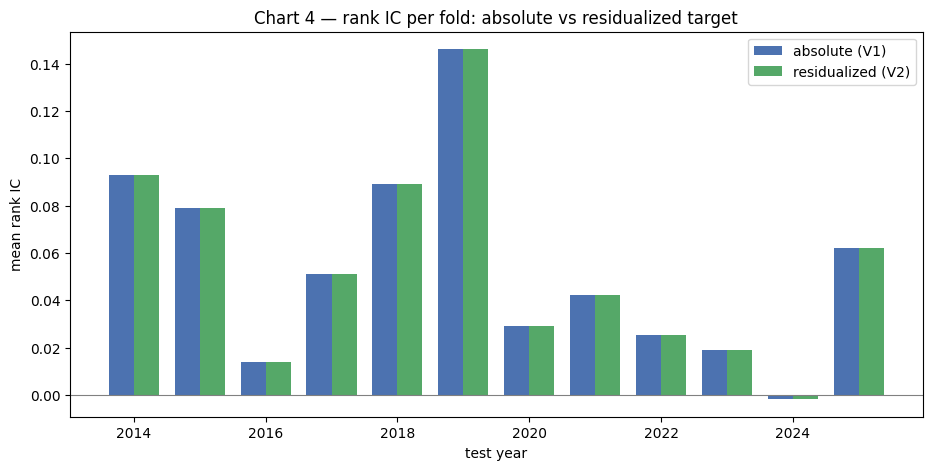

Pooled rank IC: absolute +0.0540 -> residualized +0.0540.
IC may move LESS than R2: ranking was already market-robust-ish, so the IC was less contaminated by market direction than R2 was. That contrast is itself a lesson about what each metric measures.


In [8]:
# CHART 4 — rank IC per fold, absolute vs residualized
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(yrs - w/2, sa["ic_rank"], w, label="absolute (V1)", color="#4C72B0")
ax.bar(yrs + w/2, sr["ic_rank"], w, label="residualized (V2)", color="#55A868")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("test year"); ax.set_ylabel("mean rank IC")
ax.set_title("Chart 4 — rank IC per fold: absolute vs residualized target")
ax.legend()
save_fig(fig, "ic_compare"); plt.show()
print(f"Pooled rank IC: absolute {sa.ic_rank.mean():+.4f} -> residualized {sr.ic_rank.mean():+.4f}.")
print("IC may move LESS than R2: ranking was already market-robust-ish, so the IC "
      "was less contaminated by market direction than R2 was. That contrast is itself "
      "a lesson about what each metric measures.")

  [saved: 05_ic_over_time_compare.png]


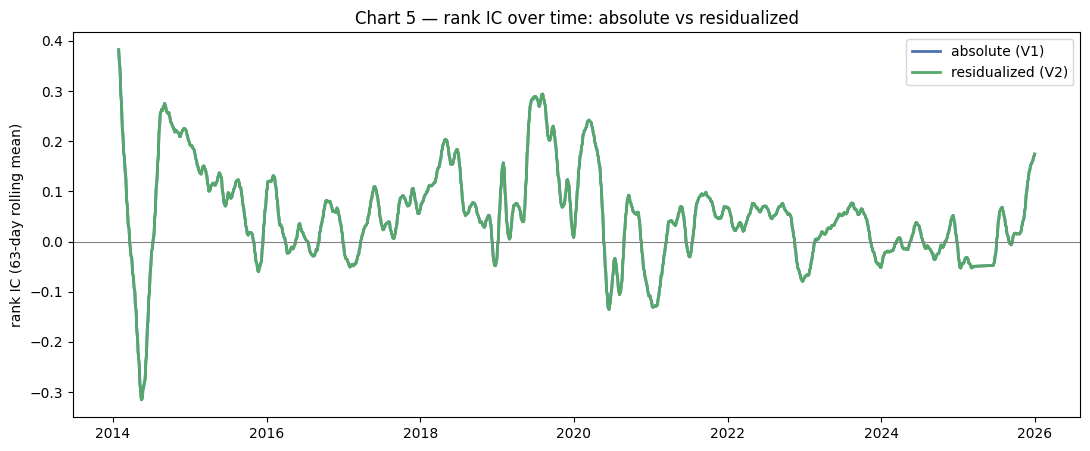

Watch whether the two lines diverge in specific regimes (e.g. 2020) — that shows WHERE the market component was distorting the absolute-target signal.


In [9]:
# CHART 5 — rank IC over time, both targets overlaid (rolling mean)
fig, ax = plt.subplots(figsize=(13, 5))
for scores, lab, c in [(S_abs, "absolute (V1)", "#4C72B0"),
                       (S_res, "residualized (V2)", "#55A868")]:
    dts, ics = [], []
    for s in scores: dts.extend(s["test_dates"]); ics.extend(s["daily_rank_ic"])
    o = np.argsort(dts); d = np.array(dts)[o]; v = np.array(ics)[o]
    ax.plot(d, pd.Series(v).rolling(63, min_periods=20).mean(), lw=2, color=c, label=lab)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("rank IC (63-day rolling mean)")
ax.set_title("Chart 5 — rank IC over time: absolute vs residualized")
ax.legend()
save_fig(fig, "ic_over_time_compare"); plt.show()
print("Watch whether the two lines diverge in specific regimes (e.g. 2020) — that "
      "shows WHERE the market component was distorting the absolute-target signal.")

  [saved: 06_weights_resid.png]


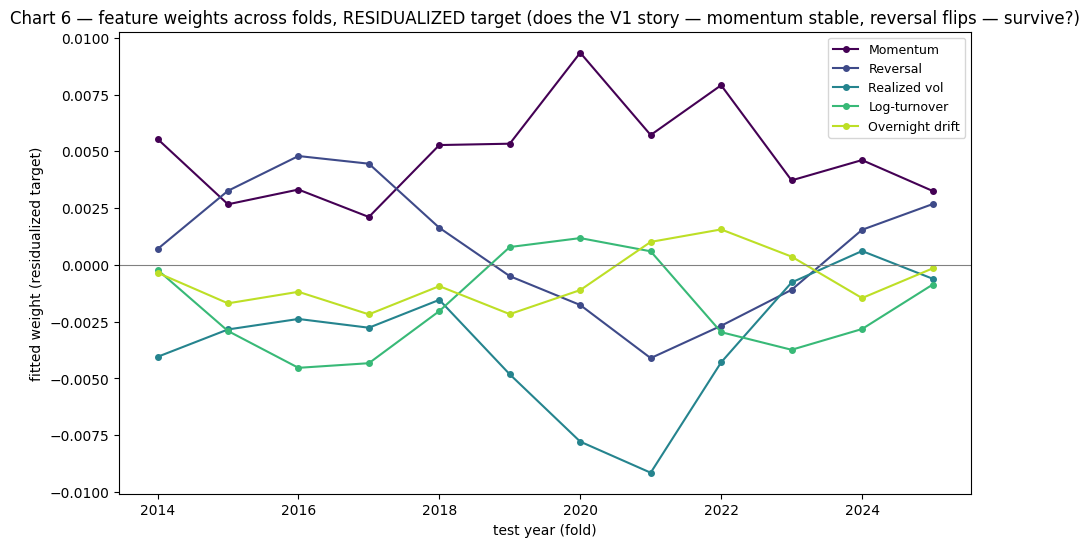

Compare to V1's weight chart: if momentum stays uniformly positive and reversal still flips sign, the feature-level findings are robust to the target choice — a strong sign they're real, not target artifacts.


In [10]:
# CHART 6 — weights across folds on the RESIDUALIZED target (compare to V1's story)
fig, ax = plt.subplots(figsize=(11, 6))
for k, r in enumerate(RAW):
    ax.plot(yrs, [wf[k+1] for wf in W_res], marker="o", ms=4, color=colors[k], label=NICE[r])
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("test year (fold)"); ax.set_ylabel("fitted weight (residualized target)")
ax.set_title("Chart 6 — feature weights across folds, RESIDUALIZED target "
             "(does the V1 story — momentum stable, reversal flips — survive?)")
ax.legend(fontsize=9)
save_fig(fig, "weights_resid"); plt.show()
print("Compare to V1's weight chart: if momentum stays uniformly positive and "
      "reversal still flips sign, the feature-level findings are robust to the "
      "target choice — a strong sign they're real, not target artifacts.")

## Cell 4 — Copy-paste summary

In [11]:
print("="*70); print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("="*70); print("COPY BELOW THIS LINE AND PASTE BACK"); print("="*70)
print("\n[variance decomposition]")
print(f"  var(absolute) {var_abs:.5f} | var(market) {var_mkt:.5f} "
      f"({100*var_mkt/var_abs:.1f}%) | var(residual) {var_res:.5f} "
      f"({100*var_res/var_abs:.1f}%)")
print("\n[ABSOLUTE target per fold]")
print(sa.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"  pooled R2 {sa.r2.mean():+.4f} | rank IC {sa.ic_rank.mean():+.4f} | days+ {sa.pct_pos.mean()*100:.0f}%")
print("\n[RESIDUALIZED target per fold]")
print(sr.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"  pooled R2 {sr.r2.mean():+.4f} | rank IC {sr.ic_rank.mean():+.4f} | days+ {sr.pct_pos.mean()*100:.0f}%")
print("\n[residualized-target weights per fold]")
wr = pd.DataFrame([wf[1:] for wf in W_res], columns=[NICE[r] for r in RAW])
wr.insert(0, "test_year", yrs)
print(wr.to_string(index=False, float_format=lambda x: f"{x:+.5f}"))
print("="*70)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_v2
    01_market_component.png
    02_target_dist_compare.png
    03_r2_compare.png
    04_ic_compare.png
    05_ic_over_time_compare.png
    06_weights_resid.png
COPY BELOW THIS LINE AND PASTE BACK

[variance decomposition]
  var(absolute) 0.01481 | var(market) 0.00424 (28.6%) | var(residual) 0.01057 (71.4%)

[ABSOLUTE target per fold]
 test_year      r2  ic_rank  pct_pos
      2014 -0.1107  +0.0930  +0.7172
      2015 -0.0305  +0.0791  +0.7702
      2016 -0.0029  +0.0141  +0.5425
      2017 -0.0142  +0.0513  +0.6653
      2018 -0.0846  +0.0890  +0.7154
      2019 +0.0091  +0.1460  +0.7224
      2020 -0.0249  +0.0291  +0.5339
      2021 -0.0776  +0.0421  +0.5887
      2022 -0.0311  +0.0252  +0.6492
      2023 -0.0113  +0.0189  +0.6612
      2024 -0.0086  -0.0018  +0.5285
      2025 -0.1185  +0.0623  +0.7366
  pooled R2 -0.0421 | rank IC +0.0540 | days+ 65%

[RESIDUALIZED target per fold]
 test_year      r2  ic_rank 

## How to read V2

- **R2 jump (Chart 3)** = how much of V1's low R2 was the market-direction ceiling
  (cause #1). A big jump confirms the V1 decomposition; what R2 *remains* low is
  the combined residue of regime-varying weights (#2) and possible nonlinearity (#3),
  still confounded and to be peeled apart next.
- **IC change (Chart 4/5)** may be smaller than the R2 change — ranking was already
  less market-contaminated than magnitude. The R2-vs-IC contrast is the lesson.
- **Weights (Chart 6)** vs V1: if momentum stays stably positive and reversal still
  flips, the feature findings are robust to the target definition — real structure.

**Next fork (not built here):** (1) V3 target — official Nifty 500 residualization;
(2) peel #2 from #3 — test nonlinear terms out-of-sample under the same purge, the
discriminating test for genuine curvature vs regime-varying linear structure.